<a href="https://colab.research.google.com/github/faisu6339-glitch/RAG/blob/main/Embeddings(Part_1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Introduction to Embeddings in RAG

In **Retrieval-Augmented Generation (RAG)**, **embeddings** are the mathematical foundation that allows LLMs to find and use relevant external information.

At a high level, an embedding is a **numerical representation** of data (usually text, but can also be images or audio) that captures its semantic meaning.

---

### 1. What Exactly is an Embedding?
An embedding converts a piece of text (like a word, sentence, or entire paragraph) into a **vector**—a long list of numbers (e.g., a list of 1536 numbers).

* **Semantic Space**: Think of these numbers as coordinates in a highly dimensional space.
* **Distance = Meaning**: If two pieces of text have similar meanings (e.g., "cat" and "kitten", or "How to reset password" and "Password recovery steps"), their vectors will be positioned close to each other in this space.
* **How they are made**: They are generated by specialized machine learning models (like OpenAI's text-embedding-3, Cohere, or Hugging Face's Sentence-Transformers).

For example:

Sentence 1: I love machine learning.

Sentence 2: I enjoy studying AI.


An embedding model converts them into vectors such as:

Sentence 1 = [0.25, 0.81, 0.42, 0.19]

Sentence 2 = [0.27, 0.79, 0.45, 0.21]



These are illustrative values, not actual model outputs.

Because the sentences have related meanings, their vectors may be close in the embedding space.

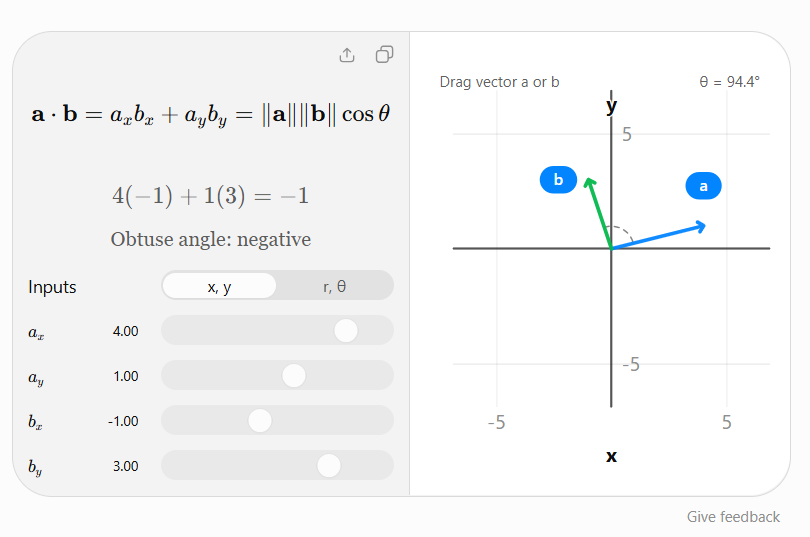

### 2. Why are Embeddings Crucial for RAG?

Standard search relies on matching exact keywords (lexical search). If you search for "physician", keyword search might miss documents containing "doctor".

RAG relies on **semantic search**, powered by embeddings, to solve this. Here is how it works step-by-step:

1. **Data Ingestion (Chunking & Embedding)**:
   * Your custom knowledge base (PDFs, docs, databases) is split into smaller, manageable chunks.
   * Each chunk is passed through an embedding model to get its vector representation.
   * These vectors are stored in a **Vector Database** (like Pinecone, Chroma, or Milvus).

2. **Retrieval (User Query to Vector)**:
   * When a user asks a question, the query is converted into a vector using the *same* embedding model.
   * The system performs a **similarity search** (using mathematical metrics like *Cosine Similarity*) comparing the query vector against all stored document vectors.
   * The most similar document chunks are retrieved.

3. **Generation (LLM Context)**:
   * The retrieved text chunks are combined with the user's original query as "context" and sent to the LLM.
   * The LLM uses this context to generate a highly accurate, grounded response.

In [1]:

!pip install -q -U \
    langchain \
    langchain-nvidia-ai-endpoints \
    langchain-openai \
    langchain-huggingface \
    sentence-transformers \
    transformers \
    scikit-learn \
    numpy \
    matplotlib \
    faiss-cpu \
    chromadb


In [2]:

from google.colab import userdata
import os

os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")

print("NVIDIA API key configured successfully!")


NVIDIA API key configured successfully!


# Program 1: Understand embeddings using Python

In [3]:
import numpy as np

sentence1 = np.array([0.25, 0.81, 0.42, 0.19])

sentence2 = np.array([0.27, 0.79, 0.45, 0.21])

print("Sentence 1 Vector:", sentence1)
print("Sentence 2 Vector:", sentence2)

print("Cosine Similarity:", np.dot(sentence1, sentence2))
print("\nVector Dimension: ", len(sentence1))

Sentence 1 Vector: [0.25 0.81 0.42 0.19]
Sentence 2 Vector: [0.27 0.79 0.45 0.21]
Cosine Similarity: 0.9363000000000001

Vector Dimension:  4


# Program 1.1: Generate actual embeddings using NVIDIA API
Now we'll generate real embeddings instead of manually creating vectors.

In [4]:
%pip uninstall -y transformers sentence-transformers
%pip install -q sentence-transformers

Found existing installation: transformers 5.24.1
Uninstalling transformers-5.24.1:
  Successfully uninstalled transformers-5.24.1
Found existing installation: sentence-transformers 6.3.0
Uninstalling sentence-transformers-6.3.0:
  Successfully uninstalled sentence-transformers-6.3.0


In [5]:
from sentence_transformers import SentenceTransformer

print("Initializing embedding model...")

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

text = "Artificial Intelligence is transforming technology."

vector = model.encode(text)

print("\nSuccessfully generated embeddings!")
print("Original text:", text)
print("\nGenerated Embedding (first 10 dimensions):")
print(vector[:10].tolist())

print("\nEmbedding Dimensions:", len(vector))

Initializing local HuggingFace embeddings model (all-MiniLM-L6-v2) directly...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


Successfully generated embeddings locally!
Original text: Artificial Intelligence is transforming technology.

Generated Embedding (truncated 10 dims): [0.025519363582134247, 0.02384963445365429, 0.08101905137300491, -0.017410239204764366, 0.03706879913806915, -0.02750427834689617, -0.023116134107112885, 0.029141893610358238, 0.0006132795242592692, -0.015279150567948818] ...

Embedding Dimensions: 384


Understanding the code:
- NVIDIAEmbeddings: Connects to an NVIDIA embedding model.
- embed_query(): Converts one query into an embedding.
- vector: Contains the numerical representation.
- len(vector): Gives the embedding dimension.
The exact output dimension depends on the selected model.

### 3. Word Embeddings vs. Sentence Embeddings

To understand embeddings properly, it is vital to distinguish between **Word Embeddings** and **Sentence (or Document) Embeddings**.

| Feature | Word Embeddings | Sentence Embeddings |
| :--- | :--- | :--- |
| **Granularity** | Represent individual words as vectors. | Represent whole sentences or paragraphs as a single vector. |
| **Context Awareness** | Often static (e.g., Word2Vec, GloVe). The word "bank" has the same vector in "river bank" and "money bank". | Highly contextual (e.g., Sentence-Transformers, BERT). Captures the meaning of the entire sentence context. |
| **Common Models** | Word2Vec, GloVe, FastText. | Sentence-Transformers (`all-MiniLM-L6-v2`), OpenAI Ada, Cohere. |
| **Primary Use Case** | Word analogies (King - Man + Woman = Queen), synonyms. | Semantic search, RAG, document clustering, sentence similarity. |

#### Hands-on Code: Comparing Word and Sentence Level Meaning

Let's see how we can analyze meaning at both levels.

We will define three sentences:
1. *"The bank of the river is muddy."*
2. *"The financial bank is closed today."*
3. *"The river bank is covered in moss."*

If we look at individual words (Word Embeddings without context), the word **"bank"** might get the same vector in all three. However, with **Sentence Embeddings**, Sentence 1 and Sentence 3 will have vectors that are very close to each other, while Sentence 2 will be far away.

In [7]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Initialize our Sentence Transformer model
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

sentences = [
    "The bank of the river is muddy.",         # River environment
    "The financial bank is closed today.",     # Finance environment
    "The river bank is covered in moss."
]

# 1. Generate sentence-level embeddings
embeddings = model.encode(sentences)

# 2. Compute semantic similarity matrix
sim_s1_s2 = cosine_similarity([embeddings[0]], [embeddings[1]])[0][0]
sim_s1_s3 = cosine_similarity([embeddings[0]], [embeddings[2]])[0][0]

print(f"Sentence 1: '{sentences[0]}'")
print(f"Sentence 2: '{sentences[1]}'")
print(f"Sentence 3: '{sentences[2]}'")
print("-" * 50)
print(f"Cosine Similarity between River Bank (S1) and Money Bank (S2): {sim_s1_s2:.4f}")
print(f"Cosine Similarity between River Bank (S1) and Mossy River Bank (S3): {sim_s1_s3:.4f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence 1: 'The bank of the river is muddy.'
Sentence 2: 'The financial bank is closed today.'
Sentence 3: 'The river bank is covered in moss.'
--------------------------------------------------
Cosine Similarity between River Bank (S1) and Money Bank (S2): 0.1875
Cosine Similarity between River Bank (S1) and Mossy River Bank (S3): 0.4921


### Program 2: The Limitation of Word-Level Overlap (Keyword/Bag-of-Words representation)
If we use simple word-level mappings (like Count Vectorization/Bag-of-Words), sentences that share the exact same words but have totally opposite meanings will appear identical.

Let's test these two sentences:
* **Sentence A:** *"The dog chased the cat."*
* **Sentence B:** *"The cat chased the dog."*

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sentences_word = [
    "The dog chased the cat.",
    "The cat chased the dog."
]

# Using a basic Count Vectorizer (Word-level count representation)
vectorizer = CountVectorizer()
word_vectors = vectorizer.fit_transform(sentences_word).toarray()

sim_word = cosine_similarity([word_vectors[0]], [word_vectors[1]])[0][0]

print("Vocabulary extracted:", vectorizer.get_feature_names_out())
print("Sentence A Vector:", word_vectors[0])
print("Sentence B Vector:", word_vectors[1])
print(f"Word-level Overlap Similarity: {sim_word:.4f} (Perfect 1.0 similarity, despite opposite meanings!)")

Vocabulary extracted: ['cat' 'chased' 'dog' 'the']
Sentence A Vector: [1 1 1 2]
Sentence B Vector: [1 1 1 2]
Word-level Overlap Similarity: 1.0000 (Perfect 1.0 similarity, despite opposite meanings!)


### Program 3: Sentence Embeddings solving Syntax & Word Order
Now we will pass the exact same sentences to our contextual sentence-level embedding model. Because Transformer-based sentence models pay attention to word ordering, syntax, and agent-object relationships, they can differentiate between who chased whom.

In [9]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# Loading the same model as configured above
sentence_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

sentences_seq = [
    "The dog chased the cat.",
    "The cat chased the dog."
]

# Encode whole sequences contextually
seq_embeddings = sentence_model.encode(sentences_seq)

sim_seq = cosine_similarity([seq_embeddings[0]], [seq_embeddings[1]])[0][0]

print(f"Sentence Embedding Similarity: {sim_seq:.4f}")
print("Notice that similarity is high because the vocabulary is similar, but it is NOT 1.0!")
print("The model successfully distinguishes the syntax changes.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence Embedding Similarity: 0.9913
Notice that similarity is high because the vocabulary is similar, but it is NOT 1.0!
The model successfully distinguishes the syntax changes.


In [6]:
import sys
import transformers
import sentence_transformers
import torch

print("Python:", sys.version)
print("Transformers:", transformers.__version__)
print("Sentence Transformers:", sentence_transformers.__version__)
print("PyTorch:", torch.__version__)

id='nvidia/nv-embed-v1' model_type='embedding' client='NVIDIAEmbeddings' endpoint=None aliases=['ai-nv-embed-v1'] supports_tools=False supports_structured_output=False supports_thinking=False thinking_prefix=None no_thinking_prefix=None thinking_param_enable=None thinking_param_disable=None base_model=None deprecated=False
id='nvidia/nv-embedqa-e5-v5' model_type='embedding' client='NVIDIAEmbeddings' endpoint=None aliases=None supports_tools=False supports_structured_output=False supports_thinking=False thinking_prefix=None no_thinking_prefix=None thinking_param_enable=None thinking_param_disable=None base_model=None deprecated=False
id='NV-Embed-QA' model_type='embedding' client='NVIDIAEmbeddings' endpoint='https://ai.api.nvidia.com/v1/retrieval/nvidia/embeddings' aliases=['ai-embed-qa-4'] supports_tools=False supports_structured_output=False supports_thinking=False thinking_prefix=None no_thinking_prefix=None thinking_param_enable=None thinking_param_disable=None base_model=None depre

# Program 4: Generate word embeddings using Word2Vec

In [10]:

!pip install -q gensim


In [13]:
from gensim.models import Word2Vec

sentences = [
    ["machine", "learning", "is", "interesting"],
    ["deep", "learning", "uses", "neural", "networks"],
    ["artificial", "intelligence", "is", "powerful"],
    ["machine", "learning", "uses", "data"]
]

model=Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4,seed=42)
vector=model.wv["learning"]

# Get word embedding
vector = model.wv["learning"]

print("Word:", "learning")
print("Embedding:", vector)
print("Dimensions:", len(vector))

Word: learning
Embedding: [-8.2178619e-03  5.4801246e-03  3.0922680e-03 -1.2208550e-03
 -1.3398413e-03  7.1750795e-03 -8.2823038e-03  3.9470829e-03
 -5.9719449e-03 -8.1167622e-03  5.2796665e-04  9.5162131e-03
  4.7162934e-03  5.2230451e-03  4.3514064e-03  5.7241195e-03
  2.6303050e-04 -7.4406210e-03  6.7963172e-03 -9.9157612e-04
  4.9230821e-06 -2.5847740e-03 -6.3509955e-03  8.5382145e-03
  5.6334916e-03  2.8760410e-03 -1.9522497e-03  6.4575709e-03
  9.0998993e-04 -1.1336540e-03 -9.9182385e-04 -5.4577482e-03
 -8.1589287e-03  1.0905785e-03  7.7599776e-03 -8.7244324e-03
  7.1690003e-03  6.5524615e-03 -4.4673900e-03  2.6356278e-03
 -6.6972696e-03  5.1639420e-03  4.0124846e-03 -2.9117432e-03
 -8.6447475e-03  9.4140759e-03 -1.0879347e-03  7.8630028e-03
  3.5604143e-03  5.5686808e-03  5.2006394e-03 -6.1079059e-03
 -2.7210913e-03 -6.6582923e-04 -4.5464763e-05 -9.1241896e-03
  9.3075115e-04 -6.9167130e-03  4.8690233e-03  3.6624365e-03
  8.4543070e-03  4.8979376e-03 -2.6694448e-03  9.3534570e-0

# Program 5: Generate sentence embeddings

In [14]:

from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

sentences = [
    "Machine learning is interesting.",
    "Deep learning uses neural networks.",
    "Artificial intelligence is powerful."
]

vectors = model.encode(sentences)

for sentence, vector in zip(sentences, vectors):

    print("\nSentence:", sentence)
    print("Embedding:", vector)
    print("Dimensions:", len(vector))


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Sentence: Machine learning is interesting.
Embedding: [-4.90368046e-02 -1.01073168e-01  8.89049172e-02  2.79693808e-02
 -1.43496301e-02 -4.40036468e-02 -4.01982330e-02 -4.06922624e-02
 -1.93220135e-02 -9.24828369e-03 -3.31848450e-02  7.71807358e-02
  1.25807477e-02  2.78469417e-02 -2.40678526e-02  6.31700363e-03
 -1.67770740e-02 -1.41561357e-03 -6.39159009e-02 -1.43631279e-01
  8.05889163e-03  5.34125720e-04  2.25362312e-02 -3.29985172e-02
  4.87808287e-02  2.22901851e-02  5.58072850e-02  3.53889074e-03
  3.15697156e-02 -5.12955338e-02 -2.33570449e-02  6.84879050e-02
 -1.05997128e-02 -2.19977517e-02 -1.06530853e-01 -8.28557927e-03
 -1.06025785e-02  6.69801608e-02  3.18156816e-02  3.62927616e-02
 -1.74082629e-02 -2.63394881e-02  5.95109016e-02 -1.30361980e-02
  9.32602659e-02  9.41426009e-02 -4.86170352e-02 -3.42222378e-02
 -1.64648369e-02  2.02882551e-02 -1.31940320e-01 -4.30189148e-02
 -5.08027412e-02  2.53172461e-02 -4.02513333e-02 -3.36275734e-02
  2.08774395e-02 -1.58884507e-02  3

# 3. Vector representation
An embedding is represented as a vector containing floating-point numbers.

For example:

\[
A=[2,3,4]
\]

\[
B=[5,6,7]
\]

Here:
- A and B are vectors.
- Each number represents one dimension.
- A vector with three values has three dimensions.

In [15]:

import numpy as np

A = np.array([2, 3, 4])

B = np.array([5, 6, 7])

# Vector addition
addition = A + B

# Vector subtraction
subtraction = A - B

# Scalar multiplication
multiplication = A * 2

# Vector dimensions
dimensions = A.shape

print("Vector A:", A)
print("Vector B:", B)

print("Addition:", addition)
print("Subtraction:", subtraction)
print("Scalar Multiplication:", multiplication)
print("Dimensions:", dimensions)


Vector A: [2 3 4]
Vector B: [5 6 7]
Addition: [ 7  9 11]
Subtraction: [-3 -3 -3]
Scalar Multiplication: [4 6 8]
Dimensions: (3,)


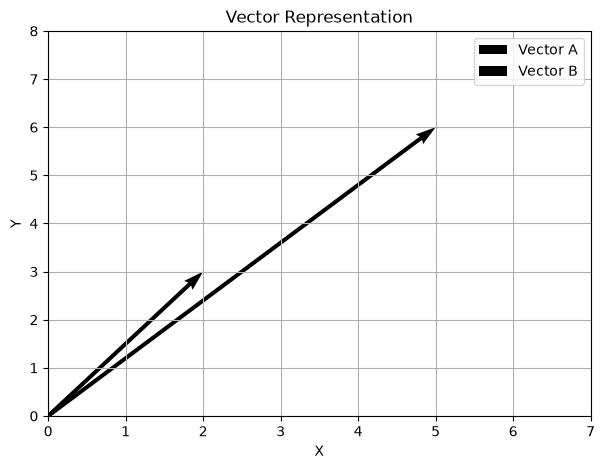

In [16]:

import numpy as np
import matplotlib.pyplot as plt

A = np.array([2, 3])
B = np.array([5, 6])

plt.figure(figsize=(7, 5))

plt.quiver(
    0, 0, A[0], A[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Vector A"
)

plt.quiver(
    0, 0, B[0], B[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    label="Vector B"
)

plt.xlim(0, 7)
plt.ylim(0, 8)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Vector Representation")

plt.grid()
plt.legend()
plt.show()


### 4. Dense vs. Sparse Embeddings

When working with Vector Search and RAG, you will frequently encounter two distinct categories of vectors: **Sparse Embeddings** and **Dense Embeddings**.

| Feature | Sparse Embeddings | Dense Embeddings |
| :--- | :--- | :--- |
| **Definition** | Very long vectors where **most values are zero** (e.g., thousands of dimensions, but only a few non-zero values). | Fixed-length, compact vectors where **almost all values are non-zero** (typically 384, 768, or 1536 dimensions). |
| **How they work** | Map specific, explicit vocabulary terms/keywords (e.g., TF-IDF, BM25, SPLADE). | Map deep semantic meanings and abstract concepts (e.g., Sentence-Transformers, OpenAI text-embeddings). |
| **Strengths** | Perfect for exact keyword matching, technical jargon, product serial numbers, and specific names. | Captures synonyms, context, paraphrase patterns, and cross-lingual meaning. |
| **Weaknesses** | Fails to recognize synonyms (misses "physician" if query is "doctor") and does not understand context. | Can struggle with precise keyword matching (e.g., searching for a specific serial ID "TX-9081" might return irrelevant but semantically similar documents). |
| **Common Algorithms** | TF-IDF, BM25, SPLADE. | BERT, RoBERTa, Ada-002, all-MiniLM-L6-v2. |

---

### Hybrid Search (The Industry Standard)
Because **Sparse** models excel at precision (finding the exact word) and **Dense** models excel at recall (finding the general concept), modern RAG databases combine both approaches into **Hybrid Search**, merging their results using a ranking algorithm like Reciprocal Rank Fusion (RRF).

#### Program 6: Comparing Sparse vs. Dense Vectors in Python
Let's write code to construct and compare both a **Sparse Vector** (using TF-IDF) and a **Dense Vector** (using Sentence Transformers) for the same text chunk.

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer
import numpy as np

# Sample text corpus
corpus = [
    "The quick brown fox jumps over the lazy dog.",
    "Artificial intelligence and machine learning are revolutionizing modern computer science."
]

target_text = "Artificial intelligence in computer science."

# --- 1. Generate Sparse Embeddings (TF-IDF) ---
sparse_vectorizer = TfidfVectorizer()
sparse_vectorizer.fit(corpus)
sparse_vector = sparse_vectorizer.transform([target_text]).toarray()[0]

# --- 2. Generate Dense Embeddings (Sentence Transformer) ---
dense_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
dense_vector = dense_model.encode(target_text)

# Print comparisons
print("=== SPARSE EMBEDDING (TF-IDF) ===")
print("Dimension size:", len(sparse_vector))
print("Number of non-zero elements:", np.count_nonzero(sparse_vector))
print("Vector representation (contains mostly zeros):\n", sparse_vector)

print("\n" + "="*40 + "\n")

print("=== DENSE EMBEDDING (Sentence Transformer) ===")
print("Dimension size:", len(dense_vector))
print("Number of non-zero elements:", np.count_nonzero(dense_vector))
print("Vector representation (truncated first 15 values, fully populated float values):\n", dense_vector[:15])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== SPARSE EMBEDDING (TF-IDF) ===
Dimension size: 18
Number of non-zero elements: 4
Vector representation (contains mostly zeros):
 [0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.  0.  0.  0.  0.  0.  0.  0.5 0. ]


=== DENSE EMBEDDING (Sentence Transformer) ===
Dimension size: 384
Number of non-zero elements: 384
Vector representation (truncated first 15 values, fully populated float values):
 [-0.01645906  0.01739406 -0.00691334  0.01956797 -0.01266958 -0.07980593
 -0.01794109  0.06262659 -0.03250152  0.042015   -0.05568723 -0.01054274
  0.02562982 -0.02664327 -0.04994041]


# Program 7: Generate sparse vectors using TF-IDF

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

documents = [
    "Machine learning is interesting",
    "Deep learning uses neural networks",
    "Machine learning uses data",
    "Python is used in artificial intelligence"
]
vectorizer=TfidfVectorizer()
sparse_vector=vectorizer.fit_transform(documents)

print("Vocabulary:", vectorizer.get_feature_names_out())
print("Sparse Vector:", sparse_vector)


print("\nDense Representation:")
print(sparse_vector.toarray())


Vocabulary: ['artificial' 'data' 'deep' 'in' 'intelligence' 'interesting' 'is'
 'learning' 'machine' 'networks' 'neural' 'python' 'used' 'uses']
Sparse Vector: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 19 stored elements and shape (4, 14)>
  Coords	Values
  (0, 8)	0.48426290003607125
  (0, 7)	0.3920525532545391
  (0, 6)	0.48426290003607125
  (0, 5)	0.6142260844216119
  (1, 7)	0.3179927614076589
  (1, 2)	0.4981971092712959
  (1, 13)	0.3927843233041577
  (1, 10)	0.4981971092712959
  (1, 9)	0.4981971092712959
  (2, 8)	0.48426290003607125
  (2, 7)	0.3920525532545391
  (2, 13)	0.48426290003607125
  (2, 1)	0.6142260844216119
  (3, 6)	0.3325241986862672
  (3, 11)	0.4217647821447532
  (3, 12)	0.4217647821447532
  (3, 3)	0.4217647821447532
  (3, 0)	0.4217647821447532
  (3, 4)	0.4217647821447532

Dense Representation:
[[0.         0.         0.         0.         0.         0.61422608
  0.4842629  0.39205255 0.4842629  0.         0.         0.
  0.         0.        ]
 [0.   

# Program 8: Generate dense embeddings

In [20]:

from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

documents = [
    "Machine learning is interesting",
    "Deep learning uses neural networks",
    "Machine learning uses data",
    "Python is used in artificial intelligence"
]

dense_vectors = model.encode(documents)

print("Dense Embeddings:")
print(dense_vectors)

print("\nShape:")
print(dense_vectors.shape)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Dense Embeddings:
[[-0.0725374  -0.09454747  0.09703179 ...  0.07484254 -0.02442318
  -0.03123236]
 [-0.1011467  -0.01303027  0.07322454 ...  0.06143842  0.03814851
  -0.0396979 ]
 [-0.01347191  0.0252954   0.02811778 ... -0.00152268  0.01468257
  -0.08045412]
 [-0.05312615  0.01051808 -0.03766897 ...  0.12908077  0.20330107
  -0.03007866]]

Shape:
(4, 384)


# 5. Cosine similarity
Extremely important
Cosine similarity measures the similarity between two vectors based on the angle between them.

Formula:
\[
\text{Cosine Similarity}=
\frac{A\cdot B}{\|A\|\|B\|}
\]

Interpretation:
Value	Meaning
+1	Same direction
0	Perpendicular vectors
-1	Opposite direction

Numerical example
Suppose:

\[
A=[1,2,3]
\]

\[
B=[2,4,6]
\]

Their cosine similarity is 1 because both vectors point in exactly the same direction.

# Program 9: Calculate cosine similarity manually

In [21]:

import numpy as np

A = np.array([1, 2, 3])

B = np.array([2, 4, 6])

# Calculate dot product
dot_product = np.dot(A, B)

# Calculate vector magnitudes
magnitude_A = np.linalg.norm(A)

magnitude_B = np.linalg.norm(B)

# Calculate cosine similarity
similarity = dot_product / (
    magnitude_A * magnitude_B
)

print("Dot Product:", dot_product)

print("Magnitude A:", magnitude_A)

print("Magnitude B:", magnitude_B)

print("Cosine Similarity:", similarity)


Dot Product: 28
Magnitude A: 3.7416573867739413
Magnitude B: 7.483314773547883
Cosine Similarity: 1.0


# Program 10: Cosine similarity using Scikit-learn

In [22]:

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

A = np.array([[1, 2, 3]])

B = np.array([[2, 4, 6]])

similarity = cosine_similarity(A, B)

print("Cosine Similarity:")
print(similarity)


Cosine Similarity:
[[1.]]


# Program 11: Compare actual sentence embeddings

In [23]:

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

sentence1 = "I love learning Artificial Intelligence."

sentence2 = "I enjoy studying Machine Learning."

# Generate embeddings
embedding1 = model.encode([sentence1])

embedding2 = model.encode([sentence2])

# Calculate similarity
similarity = cosine_similarity(
    embedding1,
    embedding2
)[0][0]

print("Sentence 1:", sentence1)
print("Sentence 2:", sentence2)

print("\nSimilarity Score:", similarity)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence 1: I love learning Artificial Intelligence.
Sentence 2: I enjoy studying Machine Learning.

Similarity Score: 0.73183024
